In [126]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from PIL import Image
print("complete")

complete


In [127]:
# getting the paths for all the things we need
DATA_DIR = "."
TRAIN_DIR = os.path.join(DATA_DIR, "train")
LABELS_FILE = os.path.join(DATA_DIR, "labels.csv")

In [128]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
labels = pd.read_csv(LABELS_FILE)


In [129]:
X = []
y = []
for index, row in labels.iterrows():
    image_id = row["id"]
    breed = row["breed"]
    image_path = os.path.join(TRAIN_DIR, image_id + ".jpg")
    image = Image.open(image_path)
    image = image.convert("RGB")
    image = image.resize((32, 32))
    image_array = np.array(image)
    image_array = image_array.flatten()
    X.append(image_array)
    y.append(breed)
    
X = np.array(X, dtype=np.float32)
y = np.array(y)
X = X / 255.0

print("Number of images:", len(X))
print("Number of features per image:", X.shape[1])
print("Number of breeds:", len(np.unique(y)))
print("Feature matrix shape:", X.shape)

Number of images: 10222
Number of features per image: 3072
Number of breeds: 120
Feature matrix shape: (10222, 3072)


In [130]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Number of training images:", len(X_train))
print("Number of validation images:", len(X_val))

Number of training images: 8177
Number of validation images: 2045


In [131]:
model = LogisticRegression(C = 0.01,max_iter=1000, solver="lbfgs")
model.fit(X_train, y_train)
print("complete")

complete


In [132]:
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print("Validation accuracy percentage:", accuracy * 100)
print("\nHow well it did:")
print(classification_report(y_val, y_pred, zero_division=0))

Validation accuracy percentage: 5.378973105134474

How well it did:
                                precision    recall  f1-score   support

                 affenpinscher       0.04      0.06      0.05        16
                  afghan_hound       0.05      0.09      0.06        23
           african_hunting_dog       0.14      0.12      0.13        17
                      airedale       0.00      0.00      0.00        22
american_staffordshire_terrier       0.00      0.00      0.00        15
                   appenzeller       0.07      0.06      0.06        16
            australian_terrier       0.02      0.05      0.03        21
                       basenji       0.08      0.09      0.09        22
                        basset       0.00      0.00      0.00        16
                        beagle       0.04      0.05      0.04        21
            bedlington_terrier       0.22      0.22      0.22        18
          bernese_mountain_dog       0.03      0.09      0.05      

In [133]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_val_std = scaler.transform(X_val)

pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_std)   # learn components from training data
X_val_pca = pca.transform(X_val_std)           # reuse them on validation data

print("Kept", pca.n_components_, "components")


Kept 287 components


In [134]:
pca_model = LogisticRegression(C=0.001, max_iter=1000, solver="lbfgs")
pca_model.fit(X_train_pca, y_train)                  # train on PCA features

y_pred_pca = pca_model.predict(X_val_pca)            # predict on PCA features
print("Train accuracy:", accuracy_score(y_train, pca_model.predict(X_train_pca)) * 100)
print("Validation accuracy:", accuracy_score(y_val, y_pred_pca) * 100)
print(classification_report(y_val, y_pred_pca, zero_division=0))


Train accuracy: 21.927357221474868
Validation accuracy: 5.623471882640587
                                precision    recall  f1-score   support

                 affenpinscher       0.04      0.06      0.05        16
                  afghan_hound       0.06      0.09      0.07        23
           african_hunting_dog       0.11      0.12      0.11        17
                      airedale       0.00      0.00      0.00        22
american_staffordshire_terrier       0.00      0.00      0.00        15
                   appenzeller       0.00      0.00      0.00        16
            australian_terrier       0.02      0.05      0.03        21
                       basenji       0.14      0.14      0.14        22
                        basset       0.00      0.00      0.00        16
                        beagle       0.04      0.05      0.04        21
            bedlington_terrier       0.19      0.17      0.18        18
          bernese_mountain_dog       0.02      0.04      0.03

In [135]:
for c in [0.0001, 0.001, 0.01, 0.1, 1]:
    m = LogisticRegression(C=c, max_iter=1000, solver="lbfgs")
    m.fit(X_train_pca, y_train)
    tr = accuracy_score(y_train, m.predict(X_train_pca)) * 100
    va = accuracy_score(y_val, m.predict(X_val_pca)) * 100
    print(f"C={c:<7} train={tr:6.2f}%  val={va:5.2f}%")


C=0.0001  train=  8.79%  val= 4.21%
C=0.001   train= 21.93%  val= 5.62%
C=0.01    train= 42.30%  val= 4.40%
C=0.1     train= 59.09%  val= 3.91%
C=1       train= 68.58%  val= 3.18%


In [136]:
X_train_pca20 = pca20.fit_transform(X_train_std)   # new names so X_train_pca isn't overwritten
X_val_pca20 = pca20.transform(X_val_std)
print(X_train_pca20.shape)                          # (8177, 20)


(8177, 20)


PCA + Logistic Regression validation accuracy: 5.623471882640587


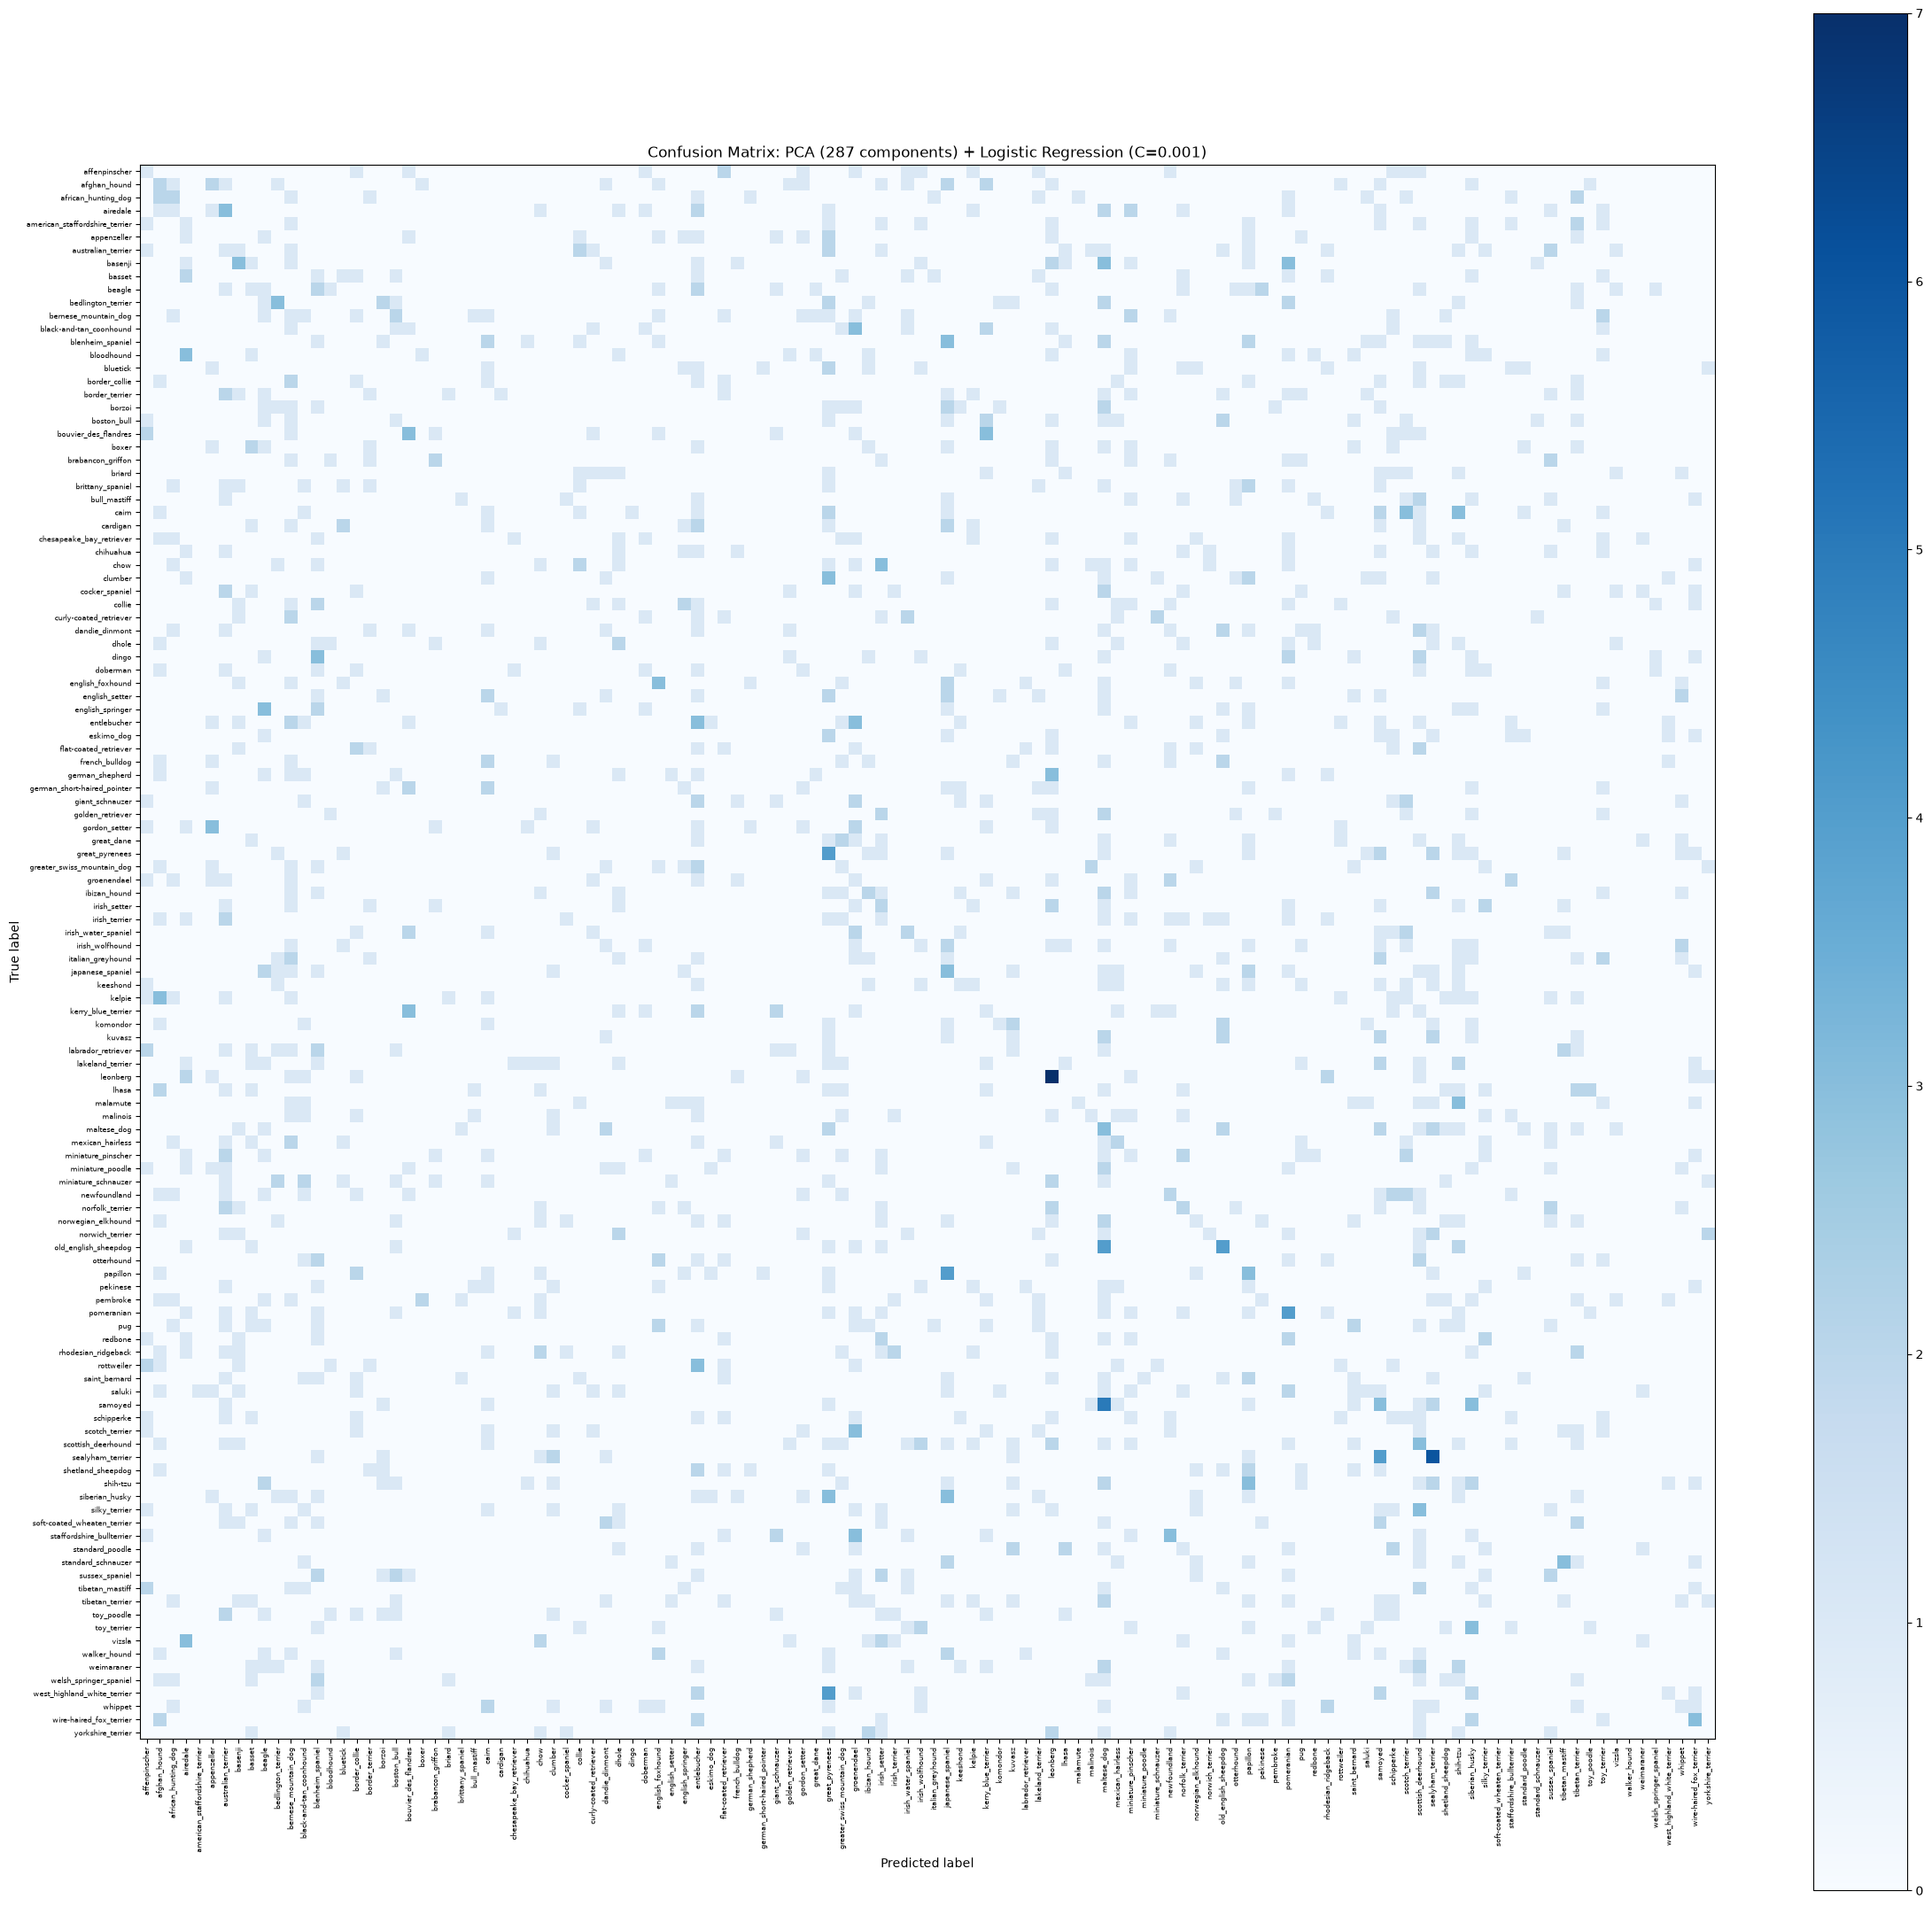

In [137]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_c = 0.001                                   # best C from the loop in cell 9
breed_names = sorted(np.unique(y_val))

pca_model = LogisticRegression(C=best_c, max_iter=1000, solver="lbfgs")
pca_model.fit(X_train_pca, y_train)              # X_train_pca = 287 components from cell 7
y_pred_pca = pca_model.predict(X_val_pca)
print("PCA + Logistic Regression validation accuracy:", accuracy_score(y_val, y_pred_pca) * 100)

cm = confusion_matrix(y_val, y_pred_pca, labels=breed_names)
fig, ax = plt.subplots(figsize=(24, 22))
ConfusionMatrixDisplay(cm, display_labels=breed_names).plot(
    ax=ax, include_values=False, xticks_rotation="vertical", cmap="Blues")
ax.tick_params(axis="both", labelsize=6)
plt.title(f"Confusion Matrix: PCA ({pca.n_components_} components) + Logistic Regression (C={best_c})")
plt.tight_layout()
plt.show()



In [139]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def LogRegPCAFunc(X_train, y_train, X_val):
    scaler = StandardScaler()
    X_train_std = scaler.fit_transform(X_train)
    X_val_std = scaler.transform(X_val)

    pca = PCA(n_components=0.95, random_state=42)
    X_train_pca = pca.fit_transform(X_train_std)
    X_val_pca = pca.transform(X_val_std)

    lrModel = LogisticRegression(C=0.001, max_iter=1000, solver="lbfgs")
    lrModel.fit(X_train_pca, y_train)
    lrPredictions = lrModel.predict(X_val_pca)
    return lrPredictions

lrPredictions = LogRegPCAFunc(X_train, y_train, X_val)
print("Validation accuracy:", accuracy_score(y_val, lrPredictions) * 100)   # should print ~5.62



Validation accuracy: 5.623471882640587
